# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset


En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.


In [4]:
# Importar librerías

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### Cargar Dataset

In [5]:
# Cargar el dataset y explorar datos

df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [6]:
# mostrar las primeras 5 filas

df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Recuerda eliminar este bloque de texto antes de subir el proyecto a tu portafolio.


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- 

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna ... .


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [7]:
# Corregir el tipo de dato

df['edad'] = df['edad'].astype(int)

df['edad'].dtype

dtype('int64')

In [8]:
# verificar cambios

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [9]:
# Estadísticas descriptivas de variables numéricas

columnas_numericas = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes',
                      'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']

df[columnas_numericas].describe().round(2)

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
count,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00
mean,38.26,30019.70,10.03,1.21,20.15,3.60,36.59
std,11.49,9833.17,3.16,1.11,10.88,0.69,34.48
min,18.00,8000.00,1.00,0.00,0.00,1.00,0.00
25%,30.00,23127.10,8.00,0.00,12.31,3.10,0.00
50%,38.00,30023.74,10.00,1.00,19.73,3.60,30.70
75%,46.00,36768.44,12.00,2.00,27.29,4.10,58.22
max,75.00,74790.84,25.00,8.00,75.51,5.00,244.69


### Diagnóstico inicial de variables numéricas

- `edad` — Rango de 18 a 75 años, con media de 38.3 y mediana de 38. La distribución es simétrica y no hay valores fuera de lo esperado.
- `nivel_ingreso` — Va de 8,000 a 74,790, con media y mediana cercanas a 30,000. Es mayormente simétrica, aunque el máximo está lejos del Q3 (36,768), lo que indica algunos clientes con ingresos personales altos.
- `visitas_mes` — Entre 1 y 25 visitas, con mediana de 10. Distribución simétrica; todos los clientes visitaron la plataforma al menos una vez en el mes.
- `compras_mes` — Entre 0 y 8 compras, con mediana de 1. Al menos el 25% de los clientes no realizó compras en el mes.
- `gasto_publicidad_dirigida` — Va de 0 a 75.5, con mediana de 19.7. Hay clientes sin gasto publicitario asignado y un máximo alejado del Q3 (27.3), lo que sugiere valores atípicos altos.
- `satisfaccion` — Se mantiene dentro de la escala de 1 a 5, con media de 3.6. Tiene decimales, por lo que se trata como variable numérica continua.
- `ingreso_anual` — Va de 0 a 244.7, con Q1 = 0: al menos el 25% de los clientes no generó ingreso. La media (36.6) supera a la mediana (30.7) y la desviación estándar (34.5) es casi igual a la media, lo que indica una distribución sesgada a la derecha con concentración de ceros.

**Conclusión:** no se detectan valores imposibles ni fuera de rango, por lo que no es necesario eliminar registros. Sin embargo, el sesgo y los ceros en `ingreso_anual` y `compras_mes` justifican calcular tanto Pearson como Spearman.

#### Explorar variables binarias

#### Explorar variables categóricas

In [10]:
# Verificar que cada columna tenga únicamente dos valores posibles

columnas_binarias = ['miembro_premium', 'abandono']

for col in columnas_binarias:
    print(f"{col}: valores únicos = {sorted(df[col].unique())}")
    print(df[col].value_counts(normalize=True).round(3), "\n")

miembro_premium: valores únicos = [0, 1]
0    0.861
1    0.139
Name: miembro_premium, dtype: float64 

abandono: valores únicos = [0, 1]
0    0.849
1    0.151
Name: abandono, dtype: float64 



**Validación de variables binarias:**

- `miembro_premium` y `abandono` contienen únicamente los valores 0 y 1, por lo que no requieren transformación.

- Ambas están desbalanceadas: el 13.9% de los clientes es premium y el 15.1% abandonó la plataforma.




In [11]:
# Verificar el número de valores únicos por variable categórica

# Verificar el número de valores únicos por variable categórica
columnas_categoricas = ['tipo_dispositivo', 'region']

for col in columnas_categoricas:
    print(col, df[col].nunique(), df[col].unique())

tipo_dispositivo 3 ['móvil' 'tablet' 'escritorio']
region 4 ['norte' 'sur' 'este' 'oeste']


**Validación de variables categóricas:**
- `tipo_dispositivo` tiene 3 categorías: móvil, tablet y escritorio.
- `region` tiene 4 categorías: norte, sur, este y oeste.
  

In [12]:
# Explorar variables categóricas y cómo se distribuyen

for col in columnas_categoricas:
    print(df[col].value_counts(normalize=True).round(3), "\n")

móvil         0.655
escritorio    0.248
tablet        0.097
Name: tipo_dispositivo, dtype: float64 

norte    0.293
oeste    0.254
sur      0.248
este     0.205
Name: region, dtype: float64 



**Distribución de variables categóricas:**
- `tipo_dispositivo` está desbalanceada: el 65.5% de los clientes usa móvil, el 24.8% escritorio y solo el 9.7% tablet. Aunque tablet es el grupo minoritario, su tamaño (~1,450 clientes) permite incluirlo en el análisis, interpretando sus resultados con precaución.
- `region` presenta una distribución relativamente equilibrada: norte (29.3%), oeste (25.4%), sur (24.8%) y este (20.5%).


## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

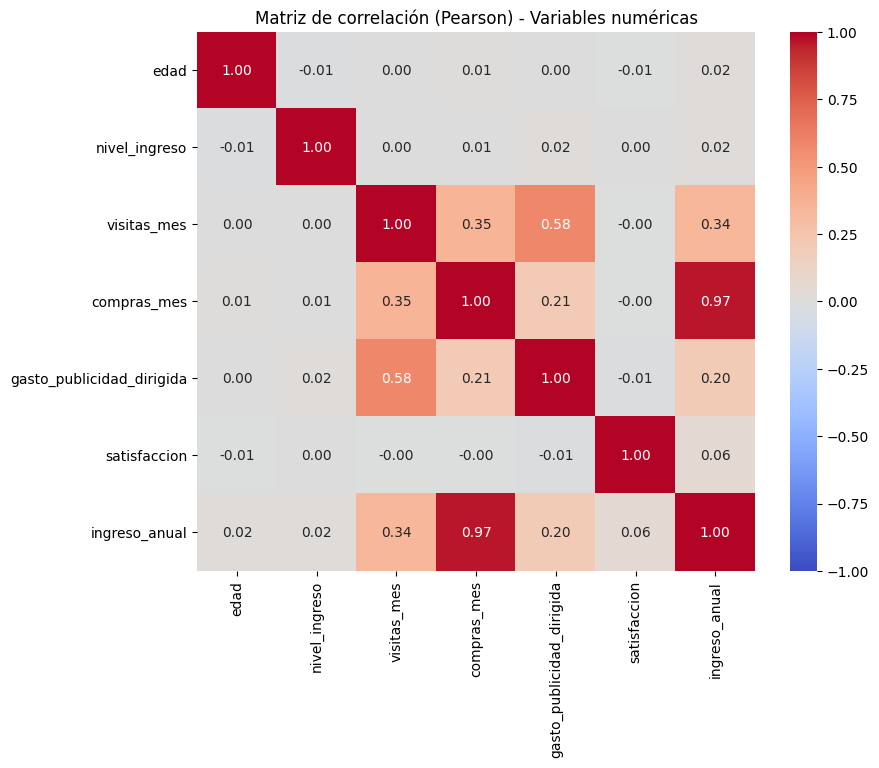

In [13]:
# Visualizar la matriz de correlación para identificar relaciones

# Visualizar la matriz de correlación para identificar relaciones
columnas_numericas = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes',
                      'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']

matriz_corr = df[columnas_numericas].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación (Pearson) - Variables numéricas')
plt.show()


### Observaciones generales (Heatmap)
- Se observa que la mayoría de las variables numéricas tienen correlaciones cercanas a 0 entre sí, lo que indica ausencia de relaciones lineales relevantes en gran parte de la matriz.
- Se identifica un bloque de variables relacionadas con la actividad del cliente: `visitas_mes`, `compras_mes`, `gasto_publicidad_dirigida` e `ingreso_anual` muestran asociaciones positivas entre sí.
- La asociación más fuerte entre variables explicativas es la de `visitas_mes` con `gasto_publicidad_dirigida` (r = 0.58): los clientes con más visitas tienden a tener asignado un mayor gasto publicitario.
- `visitas_mes` y `compras_mes` presentan una asociación positiva moderada (r = 0.35).
- `edad`, `nivel_ingreso` y `satisfaccion` no muestran asociación lineal con ninguna otra variable (r entre -0.01 y 0.06).
- No se observan correlaciones negativas relevantes.

### Observaciones respecto a `ingreso_anual`
- Presenta una asociación positiva casi perfecta con `compras_mes` (r = 0.97). Esta relación es esperada, ya que el ingreso proviene directamente de las compras, por lo que se interpreta como una relación estructural y no como un hallazgo de comportamiento.
- Presenta una asociación positiva moderada con `visitas_mes` (r = 0.34): los clientes que visitan más la plataforma tienden a generar mayor ingreso.
- Presenta una asociación positiva débil con `gasto_publicidad_dirigida` (r = 0.20). Dado que esta variable también se asocia con `visitas_mes` (r = 0.58), su relación con el ingreso podría estar influida por el nivel de visitas; no se puede concluir que la publicidad genere ingreso.
- No presenta asociación lineal relevante con `satisfaccion` (r = 0.06), `edad` (r = 0.02) ni `nivel_ingreso` (r = 0.02).



### Scatterplot general

**Decisión sobre el scatterplot general:**
Se incluye un scatterplot general, pero limitado a las variables que mostraron asociación con `ingreso_anual` en el heatmap (`visitas_mes`, `compras_mes` y `gasto_publicidad_dirigida`). Se excluyen `edad`, `nivel_ingreso` y `satisfaccion`, ya que su correlación con el resto de variables es prácticamente nula. Para mejorar la legibilidad se utilizara una muestra aleatoria de 2,000 clientes.

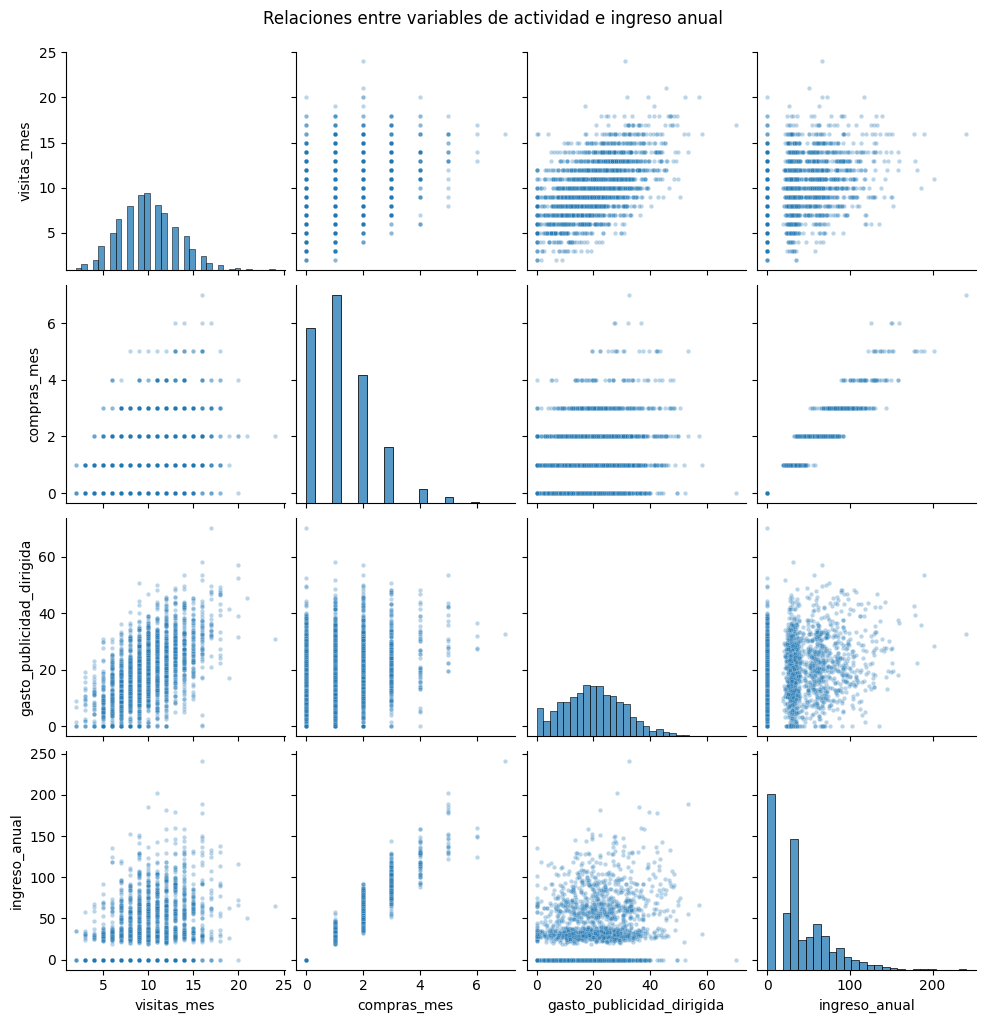

In [14]:
# Scatterplot general de las variables con asociación relevante

variables_relevantes = ['visitas_mes', 'compras_mes', 'gasto_publicidad_dirigida', 'ingreso_anual']

muestra = df[variables_relevantes].sample(2000, random_state=42)

sns.pairplot(muestra, plot_kws={'alpha': 0.3, 's': 10})
plt.suptitle('Relaciones entre variables de actividad e ingreso anual', y=1.02)
plt.show()

### Scatterplot para pares clave

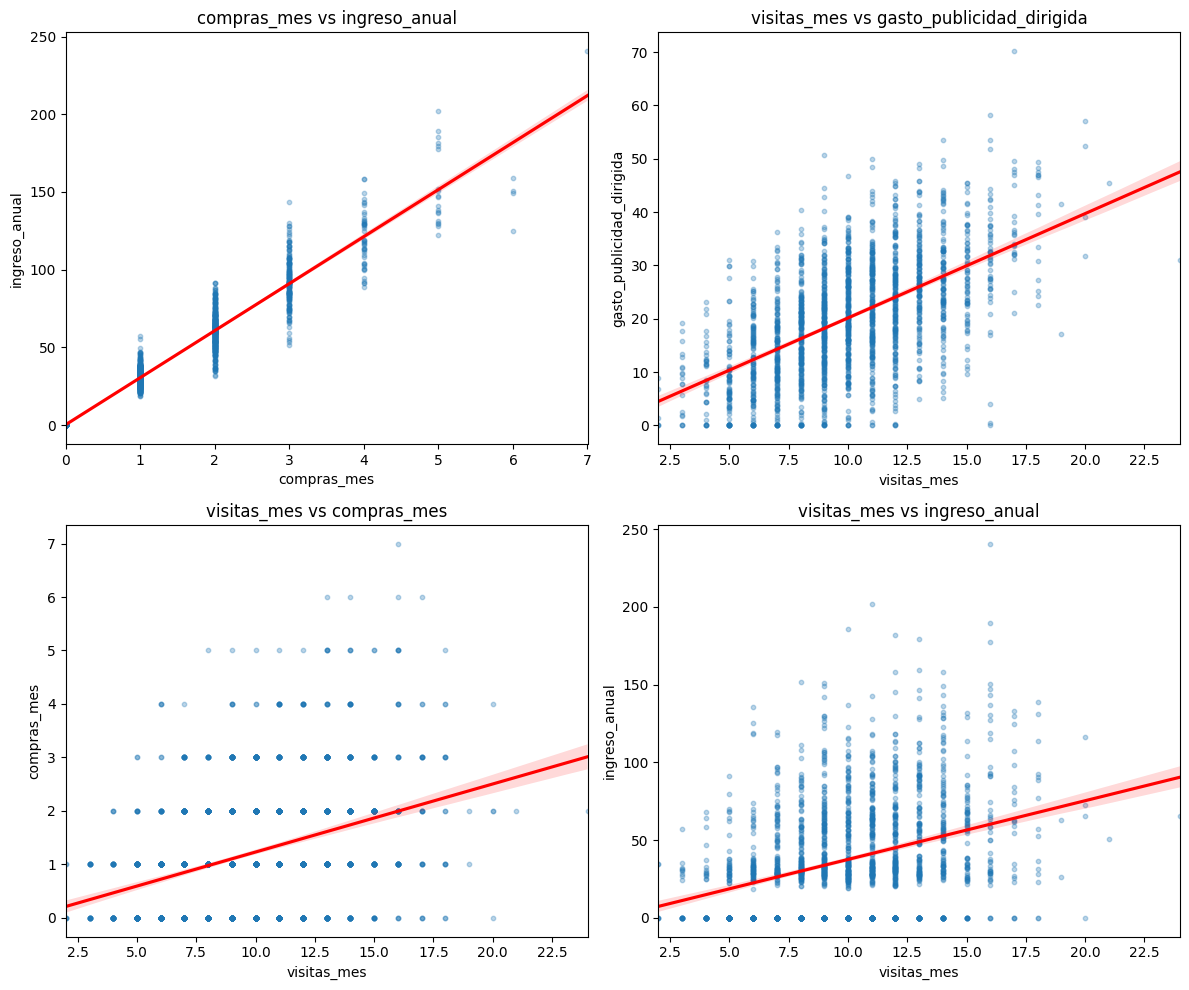

In [15]:

# Visualizar pares de variables con relaciones moderadas o fuertes

pares = [('compras_mes', 'ingreso_anual'),
         ('visitas_mes', 'gasto_publicidad_dirigida'),
         ('visitas_mes', 'compras_mes'),
         ('visitas_mes', 'ingreso_anual')]

muestra = df.sample(2000, random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (x, y) in zip(axes.flatten(), pares):
    sns.regplot(data=muestra, x=x, y=y, ax=ax,
                scatter_kws={'alpha': 0.3, 's': 10}, line_kws={'color': 'red'})
    ax.set_title(f'{x} vs {y}')

plt.tight_layout()
plt.show()

### Observaciones iniciales (Scatterplot)

**`compras_mes` vs `ingreso_anual`** (r = 0.97)
- Dirección: positiva. La línea de tendencia parte prácticamente de 0 y aumenta alrededor de 30 unidades de ingreso por cada compra adicional.
- Dispersión: baja. Los puntos forman escalones bien definidos, aunque la variación del ingreso dentro de cada escalón crece con el número de compras (de ~20–55 con 1 compra a ~120–200 con 5 compras).
- Outliers: un cliente con 7 compras e ingreso cercano a 240, y algunos con 5 compras e ingresos cercanos a 200.
- Colinealidad: muy alta. El ingreso proviene directamente de las compras, por lo que es una relación estructural esperada y no un hallazgo de comportamiento.

**`visitas_mes` vs `gasto_publicidad_dirigida`** (r = 0.58)
- Dirección: positiva.
- Dispersión: media, y creciente a medida que aumentan las visitas (forma de abanico).
- Outliers: algunos clientes con gasto superior a 55–70 y clientes con gasto 0 en casi todos los niveles de visitas.
- Colinealidad: moderada. Es la asociación más fuerte entre variables explicativas, por lo que la relación de la publicidad con el ingreso podría estar influida por las visitas.

**`visitas_mes` vs `compras_mes`** (r = 0.35)
- Dirección: positiva, con pendiente suave.
- Dispersión: alta. Para un mismo número de visitas hay clientes con 0 compras y clientes con 4–5 compras.
- Outliers: pocos clientes con 6–7 compras.
- Colinealidad: baja a moderada. Existen clientes sin compras en todo el rango de visitas (de 2 a 20): visitar más no implica necesariamente comprar.

**`visitas_mes` vs `ingreso_anual`** (r = 0.34)
- Dirección: positiva, con pendiente suave respecto a la dispersión de los datos.
- Dispersión: alta, con una franja de clientes con ingreso 0 en todos los niveles de visitas.
- Outliers: algunos clientes con ingresos superiores a 150–240.
- Colinealidad: baja a moderada. Esta relación probablemente refleja la asociación entre visitas y compras, ya que el ingreso depende de las compras.

## Sección 4 - Coeficientes de correlación y evidencia numérica

In [17]:
# Calcular correlación entre variables relevantes
# Calcular correlación entre variables relevantes

columnas_numericas = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes',
                      'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']

pearson = df[columnas_numericas].corr(method='pearson')['ingreso_anual']
spearman = df[columnas_numericas].corr(method='spearman')['ingreso_anual']

correlaciones = pd.DataFrame({'pearson': pearson, 'spearman': spearman})
correlaciones['diferencia'] = correlaciones['spearman'] - correlaciones['pearson']

correlaciones.drop('ingreso_anual').sort_values('spearman', ascending=False).round(3)


,pearson,spearman,diferencia
compras_mes,0.967,0.967,0.000
visitas_mes,0.337,0.321,-0.016
gasto_publicidad_dirigida,0.197,0.185,-0.012
satisfaccion,0.056,0.061,0.005
nivel_ingreso,0.017,0.025,0.008
edad,0.017,0.016,-0.001


**Comparación Pearson vs Spearman:**

- Los coeficientes de Pearson y Spearman son prácticamente idénticos para todas las variables (diferencia máxima de 0.016), lo que indica que las relaciones observadas son robustas pese al sesgo y la concentración de ceros en `ingreso_anual`.
- El orden de las asociaciones se mantiene con ambos métodos:
  - `compras_mes` (r ≈ 0.97): asociación muy fuerte, de carácter estructural, ya que el ingreso proviene de las compras.
  - `visitas_mes` (r ≈ 0.33): asociación positiva moderada.
  - `gasto_publicidad_dirigida` (r ≈ 0.19): asociación positiva débil, posiblemente influida por su relación con `visitas_mes`.
  - `satisfaccion`, `nivel_ingreso` y `edad` (r < 0.07): sin asociación relevante con el ingreso.
- Spearman no revela relaciones monotónicas ocultas: las variables con correlación cercana a cero bajo Pearson también lo son bajo Spearman.
- Dado el tamaño de la muestra (15,000 registros), incluso correlaciones muy bajas podrían resultar estadísticamente significativas; sin embargo, valores inferiores a 0.1 no tienen relevancia práctica para decisiones de negocio.

### Punto-biserial

In [18]:
# Calcular correlación punto biserial

from scipy.stats import pointbiserialr

columnas_binarias = ['miembro_premium', 'abandono']

for col in columnas_binarias:
    r, p = pointbiserialr(df[col], df['ingreso_anual'])
    print(f"{col}: r = {r:.3f} | p-valor = {p:.4f}")




miembro_premium: r = 0.093 | p-valor = 0.0000
abandono: r = -0.003 | p-valor = 0.7295


**Correlación punto biserial con `ingreso_anual`:**

- **`miembro_premium`** (r = 0.093, p < 0.001): asociación positiva muy débil. Los clientes premium tienden a generar un ingreso ligeramente mayor, pero la membresía explica menos del 1% de la variación del ingreso. Aunque es estadísticamente significativa, su relevancia práctica es baja. No es posible afirmar que la membresía premium genere mayor ingreso; podría ocurrir que los clientes con mayor actividad de compra sean quienes eligen suscribirse.
- **`abandono`** (r = -0.003, p = 0.73): no existe asociación. Los clientes que abandonaron la plataforma generaron un ingreso anual similar al de los clientes activos, lo que indica que el abandono no se concentra en clientes de bajo valor.

### V de Cramér

In [19]:
# Función para calcular V de Cramér

from scipy.stats import chi2_contingency

def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla)[0]
    n = tabla.sum().sum()
    k = min(tabla.shape) - 1
    return np.sqrt(chi2 / (n * k))

In [20]:
# Aplicar V de Cramér en variables relevantes

# Convertir ingreso_anual en segmentos (cuartiles)
df['segmento_ingreso'] = pd.qcut(df['ingreso_anual'], q=4, duplicates='drop')

# Pares de variables a evaluar
pares_cramer = [('tipo_dispositivo', 'segmento_ingreso'),
                ('region', 'segmento_ingreso'),
                ('tipo_dispositivo', 'region'),
                ('tipo_dispositivo', 'miembro_premium'),
                ('region', 'miembro_premium'),
                ('tipo_dispositivo', 'abandono'),
                ('region', 'abandono')]

for x, y in pares_cramer:
    v = cramers_v(df[x], df[y])
    print(f"{x} vs {y}: V = {v:.3f}")

tipo_dispositivo vs segmento_ingreso: V = 0.014
region vs segmento_ingreso: V = 0.017
tipo_dispositivo vs region: V = 0.012
tipo_dispositivo vs miembro_premium: V = 0.020
region vs miembro_premium: V = 0.013
tipo_dispositivo vs abandono: V = 0.007
region vs abandono: V = 0.015


**Asociación entre variables categóricas (V de Cramér):**

Para incluir `ingreso_anual` en este análisis, se segmentó en grupos según sus cuartiles (`segmento_ingreso`).

- Todos los pares evaluados presentan valores de V inferiores a 0.03, lo que indica asociaciones debiles.
- `tipo_dispositivo` (V = 0.014) y `region` (V = 0.017) no se asocian con el segmento de ingreso: los clientes de distintos dispositivos y regiones se distribuyen de forma similar entre los niveles de ingreso.
- Ninguna de las dos variables se asocia con `miembro_premium` ni con `abandono`, por lo que no existe un dispositivo o región donde se concentre la suscripción premium o la fuga de clientes.
- `tipo_dispositivo` y `region` son independientes entre sí.

En conjunto, estos resultados sugieren que el ingreso generado se asocia más con el comportamiento del cliente (compras y visitas) que con su perfil geográfico o tecnológico.

## Sección 5 - Interpretación de resultados para el negocio

### Hallazgo 1: Las compras mensuales son el principal indicador del ingreso generado

1) **Evidencia visual:** en el heatmap, `compras_mes` es la variable con color más intenso en la fila de `ingreso_anual`. En el scatterplot se observa una relación escalonada: cada número de compras corresponde a una franja de ingreso, y todos los clientes con 0 compras tienen ingreso 0.
2) **Evidencia numérica:** Pearson r = 0.967; Spearman ρ = 0.967.
3) **Interpretación:** los clientes que realizan más compras al mes tienden a generar mayor ingreso anual. Esta relación es en gran parte estructural, ya que el ingreso se construye a partir de las compras.
4) **No podemos afirmar:** que las compras sean un "factor de comportamiento" descubierto por el análisis; por su naturaleza, ambas variables miden prácticamente lo mismo. Tampoco podemos afirmar qué lleva a un cliente a comprar más.
5) **Implicación de negocio:** `compras_mes` es útil como indicador temprano del valor del cliente, pero no como palanca de análisis. El foco estratégico debe estar en entender qué comportamientos se asocian con que un cliente realice su primera compra y compre con mayor frecuencia, especialmente en el segmento de clientes sin compras (al menos 25% de la base).

### Hallazgo 2: Los clientes con más visitas tienden a generar mayor ingreso

1) **Evidencia visual:** el scatterplot `visitas_mes` vs `ingreso_anual` muestra una tendencia positiva con alta dispersión y una franja de clientes con ingreso 0 en todos los niveles de visitas.
2) **Evidencia numérica:** Pearson r = 0.337; Spearman ρ = 0.321. Además, `visitas_mes` se asocia con `compras_mes` (r = 0.35).
3) **Interpretación:** existe una asociación positiva moderada: los clientes más activos en la plataforma tienden a generar más ingreso. Esta relación probablemente refleja que los clientes que visitan más también tienden a comprar más.
4) **No podemos afirmar:** que aumentar las visitas genere más ingreso. Es posible que los clientes con intención de compra sean quienes visitan más, y no al revés. Además, muchos clientes visitan con frecuencia sin comprar.
5) **Implicación de negocio:** las visitas son una señal útil de interés. Los clientes con muchas visitas y 0 compras representan un segmento prioritario para estrategias de conversión (por ejemplo, recordatorios de carrito o recomendaciones personalizadas), cuyo efecto debería validarse mediante experimentos A/B.

### Hallazgo 3: El gasto en publicidad dirigida tiene una asociación débil y posiblemente engañosa con el ingreso

1) **Evidencia visual:** el scatterplot `gasto_publicidad_dirigida` vs `ingreso_anual` muestra una nube difusa, con clientes sin ingreso en todo el rango de gasto. En cambio, `visitas_mes` vs `gasto_publicidad_dirigida` muestra una relación positiva clara.
2) **Evidencia numérica:** con `ingreso_anual`, Pearson r = 0.197 y Spearman ρ = 0.185. Con `visitas_mes`, r = 0.58.
3) **Interpretación:** los clientes con mayor gasto publicitario asignado tienden a generar un ingreso ligeramente mayor, pero esta asociación es débil y podría estar influida por las visitas: la publicidad se asocia más con las visitas que con el ingreso.
4) **No podemos afirmar:** que la publicidad dirigida genere ingreso. Es posible que el sistema asigne más presupuesto publicitario a los clientes que ya visitan más la plataforma, lo que produciría una correlación sin que exista un efecto real de la publicidad.
5) **Implicación de negocio:** no se recomienda aumentar el presupuesto publicitario basándose en esta correlación. Para evaluar su efectividad real, se debería diseñar un experimento controlado (grupo con publicidad vs grupo sin publicidad) y revisar los criterios con los que se asigna el gasto a cada cliente.

### Hallazgo 4: La membresía premium tiene una asociación muy débil con el ingreso

1) **Evidencia visual:** no aplica (variable binaria).
2) **Evidencia numérica:** correlación punto biserial r = 0.093 (p < 0.001). Los clientes premium representan el 13.9% de la base.
3) **Interpretación:** los clientes premium tienden a generar un ingreso ligeramente mayor que los no premium, pero la diferencia es pequeña: la membresía explica menos del 1% de la variación del ingreso. Es estadísticamente significativa por el tamaño de la muestra, pero de baja relevancia práctica.
4) **No podemos afirmar:** que la suscripción premium haga que los clientes gasten más. Podría ocurrir que los clientes que ya compran más sean quienes deciden suscribirse.
5) **Implicación de negocio:** la membresía premium no parece diferenciar de forma importante el valor de los clientes. Antes de invertir en promocionarla como estrategia de ingreso, convendría revisar sus beneficios y medir su efecto mediante experimentación.

### Hallazgo 5: El abandono no se asocia con el ingreso generado

1) **Evidencia visual:** no aplica (variable binaria).
2) **Evidencia numérica:** correlación punto biserial r = -0.003 (p = 0.73). El 15.1% de los clientes abandonó la plataforma.
3) **Interpretación:** los clientes que abandonaron generaron un ingreso anual similar al de los clientes que siguen activos. El abandono no se concentra en clientes de bajo valor.
4) **No podemos afirmar:** cuáles son las razones del abandono ni que el ingreso no tenga ninguna relación con la retención en otros contextos o periodos.
5) **Implicación de negocio:** la fuga afecta a clientes de todos los niveles de valor, lo que la hace especialmente costosa. El equipo de Retención no debería enfocarse solo en clientes de bajo ingreso; se recomienda investigar las causas del abandono con otras fuentes (encuestas de salida, historial de uso, atención al cliente).

### Hallazgo 6: El perfil del cliente no se asocia con el ingreso

1) **Evidencia visual:** en el heatmap, `edad`, `nivel_ingreso` y `satisfaccion` aparecen en colores neutros (cercanos a 0) en todas sus combinaciones.
2) **Evidencia numérica:**
   - `satisfaccion`: r = 0.056; ρ = 0.061
   - `nivel_ingreso`: r = 0.017; ρ = 0.025
   - `edad`: r = 0.017; ρ = 0.016
   - `tipo_dispositivo` vs segmento de ingreso: V = 0.014
   - `region` vs segmento de ingreso: V = 0.017
3) **Interpretación:** ni la edad, ni el ingreso personal, ni la satisfacción, ni el dispositivo, ni la región se asocian con el ingreso que el cliente genera para la empresa. Pearson y Spearman coinciden, por lo que tampoco hay relaciones no lineales ocultas.
4) **No podemos afirmar:** que estas variables sean irrelevantes para otros objetivos del negocio (por ejemplo, la satisfacción podría relacionarse con la recomendación de la plataforma), ni que la ausencia de correlación descarte relaciones dentro de subgrupos específicos.
5) **Implicación de negocio:** segmentar a los clientes por perfil demográfico, geográfico o tecnológico no parece útil para identificar a los clientes de mayor valor. Las estrategias de crecimiento deberían basarse en el comportamiento del cliente (frecuencia de compra y actividad en la plataforma). En el caso de `satisfaccion`, sorprende su falta de relación con el ingreso, lo que sugiere revisar cómo se mide.


## Sección 6 - Limitaciones y próximos pasos

### Limitaciones

1. **Correlación no es causalidad.** El análisis identifica asociaciones, pero no permite afirmar que una variable provoque cambios en otra.
2. **Posibles variables de confusión.** Algunas asociaciones podrían explicarse por factores no incluidos en el dataset. Por ejemplo, la relación entre publicidad e ingreso podría estar influida por las visitas.
3. **Relación estructural compras–ingreso.** La correlación de r = 0.97 refleja que el ingreso proviene de las compras, por lo que no aporta información nueva sobre el comportamiento.
4. **Datos de un solo momento.** Al ser una fotografía de 2024, no es posible saber qué ocurrió primero (por ejemplo, si el cliente se volvió premium antes o después de comprar más).
5. **Criterios de publicidad desconocidos.** No se sabe cómo se asigna el gasto publicitario a cada cliente, lo que podría sesgar su correlación con el ingreso.
6. **Significancia vs relevancia.** Con 15,000 registros, asociaciones muy débiles resultan estadísticamente significativas sin ser relevantes para el negocio.

### Próximos pasos

1. **Analizar a los clientes sin compras**, especialmente los que visitan con frecuencia, para diseñar estrategias de conversión.
2. **Realizar experimentos A/B** para medir el efecto real de la publicidad dirigida y la membresía premium.
3. **Calcular la correlación parcial** entre publicidad e ingreso controlando por visitas.
4. **Investigar las causas del abandono** con otras fuentes (encuestas de salida, historial de uso), ya que afecta a clientes de todos los niveles de ingreso.